# Video offset sweep on 100 random good-frame EODs (3-fish recording)

For 100 EODs drawn at random (seed 0) from the good frames (`good_frames_better_list.csv`), my model of the emitting fish only
(fish 0; BEM σ, sink at the tail tip, the other fish as bodies) is rebuilt from the masks and midlines of video frames
`Frame + OFFSET` for OFFSET = 0, −1, …, −6 frames (0 to −120 ms at 50 fps), and compared with the same recorded EOD (L2 distance d,
patterns × −1, max |v| = 1). Offset 0 reproduces the cached model. The system matrix is built with a vectorised copy of
`build_A_shell` (`build_A_var`, checked equal to it); nothing in the shared code changes. Results are saved to
`results/eod_ground_truth_3fish/conductivities/offset_sweep_random100.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import eod_examples as ex
%matplotlib inline
from compute_electric_field import (multipole_sources, build_multipole_b, occupancy_field, build_A_shell, solve_potential, gammas,
                                    unflatten_to_grid, theta_outer)
from eod_assign import pair_voltages

OFFSETS = list(range(0, -7, -1))                                    # video frames: 0 to -120 ms at 50 fps
N_EOD, SEED = 100, 0
RES = 'results/eod_ground_truth_3fish/conductivities'; OUT = f'{RES}/debug_frames'
N = 150; h = 1 / (N - 1); CELL_CM = (912 - 1) / (N - 1) / ex.PX_PER_CM
BEM = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=100.0, eps_interior=0.0,
           sigma_skin=1 / (0.1 / 0.005 + 1 / 100.0), eps_skin=0.0)
DELTA_H = 0.005 / CELL_CM; gw, gs, gi = gammas(0.0, **BEM)
c = ex.emitter_usual_lengths(ex.use_better_list(ex.load_recording('3-fish'))); em = c['emitter']; P = c['P']

def build_A_var(occ, N_, delta_h, gnode, gskin):
    '''Vectorised build_A_shell with per-node values (water / interior σ in gnode, skin σ of interior nodes in gskin).'''
    tx, ty = theta_outer(occ); ins = occ > 0.5; idx = np.arange(N_ * N_).reshape(N_, N_); R, C, V = [], [], []
    for th, a, b in ((tx, np.s_[:-1, :], np.s_[1:, :]), (ty, np.s_[:, :-1], np.s_[:, 1:])):
        gA, gB = gnode[a], gnode[b]; gi_ = np.where(ins[a], gA, gB); gs_ = np.where(ins[a], gskin[a], gskin[b])
        t = np.nan_to_num(th)
        w = np.where(np.isnan(th), 2 / (1 / gA + 1 / gB), 1 / (t / gA + (1 - t) / gB + delta_h * (1 / gs_ - 1 / gi_)))
        R += [idx[a].ravel(), idx[b].ravel()]; C += [idx[b].ravel(), idx[a].ravel()]; V += [w.ravel()] * 2
    A = sp.coo_matrix((np.concatenate(V), (np.concatenate(R), np.concatenate(C))), shape=(N_ * N_,) * 2).tocsr()
    return (A - sp.diags(np.asarray(A.sum(axis=1)).ravel())).astype(complex)
def A_bem(fms, skip):
    occ = occupancy_field(fms, N, skip=skip); ins = occ > 0.5
    return build_A_var(occ, N, DELTA_H, np.where(ins, BEM['sigma_interior'], 1.0), np.where(ins, BEM['sigma_skin'], 1.0))
def u_em(fms, mid):
    '''My model pattern (x -1, max |v| = 1) with fish em emitting; None without a midline.'''
    if mid is None: return None
    v = -pair_voltages(unflatten_to_grid(solve_potential(A_bem(fms, em), build_multipole_b(*multipole_sources(mid, I0=1.0, sink_frac=0.0), h, N)), N).real, c['pairs'], N)
    return v / np.abs(v).max()
def heading(mid): t = (mid[-1] - mid[0]) * [-1, 1]; return np.degrees(np.arctan2(t[0], t[1]))

good = np.flatnonzero(c['assigned']['good frames'].to_numpy())
smp = np.sort(np.random.default_rng(SEED).choice(good, N_EOD, replace=False))
_fm = ex.frame_masks(c, int(c['df'].Frame.iloc[smp[0]]))
assert abs(A_bem(_fm, em) - build_A_shell(occupancy_field(_fm, N, skip=em), N, DELTA_H, gw, gs, gi)).max() < 1e-9   # = build_A_shell
print(f"{len(good)} good-frame EODs; {N_EOD} drawn (seed {SEED}); offsets {OFFSETS} frames at {c['fps']:g} fps")

6751 good-frame EODs; 100 drawn (seed 0); offsets [0, -1, -2, -3, -4, -5, -6] frames at 50 fps


## d for each offset

In [2]:
rows = []
for j in smp:
    i = c['df'].index[j]; frame = int(c['df'].Frame[i]); r, U = ex.my_patterns(c, i)
    row = dict(eod_row=i, frame=frame, gap_cm=c['assigned'].loc[i, 'gap_cm'])
    heads = {}
    for off in OFFSETS:
        fms = ex.frame_masks(c, frame + off); mds = ex.fish_midlines(fms)
        if off == 0: row['d_0'] = np.linalg.norm(U[em] - r)          # cached model at the EOD's own frame
        else:
            u = u_em(fms, mds[em]); row[f'd_{off}'] = np.nan if u is None else np.linalg.norm(u - r)
        row[f'heading_{off}'] = heading(mds[em]) if mds[em] is not None else np.nan
        heads[off] = mds[em][-1] * (P - 1) if mds[em] is not None else np.full(2, np.nan)
    row['head_moved_cm'] = np.linalg.norm(heads[0] - heads[OFFSETS[-1]]) / ex.PX_PER_CM          # over the whole window
    row['turn_deg'] = (row['heading_0'] - row[f'heading_{OFFSETS[-1]}'] + 180) % 360 - 180
    rows.append(row)
T = pd.DataFrame(rows); T.to_csv(f'{RES}/offset_sweep_random100.csv', index=False)
D = T[[f'd_{o}' for o in OFFSETS]].to_numpy()
# the solver reproduces the cache at offset 0: check on the first EOD
i0 = T.eod_row[0]; f0 = ex.frame_masks(c, int(T.frame[0])); r0, U0 = ex.my_patterns(c, i0)
assert np.isclose(np.linalg.norm(u_em(f0, ex.fish_midlines(f0)[em]) - r0), T.d_0[0], atol=1e-6)
print(f"{len(T)} EODs, {np.isnan(D).sum()} missing midlines")

100 EODs, 0 missing midlines


In [3]:
ms = lambda o: f'{1000 * o / c["fps"]:+.0f} ms'
best = np.nanargmin(D, axis=1); T['best_off'] = np.array(OFFSETS)[best]; T['d_best'] = D[np.arange(len(T)), best]; T['gain_best'] = T.d_best - T.d_0
print(f"{'offset':>8s} {'ms':>8s} {'median d':>9s} {'mean d':>7s} {'median change vs 0':>19s} {'lower than at 0':>16s}")
for k, o in enumerate(OFFSETS):
    ch = D[:, k] - D[:, 0]; ok = ~np.isnan(ch)
    print(f"{o:>8d} {ms(o):>8s} {np.nanmedian(D[:, k]):9.3f} {np.nanmean(D[:, k]):7.3f} {np.nanmedian(ch):+19.3f} {np.mean(ch[ok] < 0):15.0%}")
print(f"\nbest offset per EOD (count): " + ', '.join(f'{o} ({ms(o)}): {(T.best_off == o).sum()}' for o in OFFSETS))
print(f"d at the best offset: median {T.d_best.median():.3f} vs {T.d_0.median():.3f} at 0 (gain median {T.gain_best.median():+.3f}; "
      f"gain > 0.2 in {(T.gain_best < -0.2).sum()} EODs, > 0.5 in {(T.gain_best < -0.5).sum()})")
mv = T.head_moved_cm > 1.0
for lab, m_ in ((f'fish {em} head moved > 1 cm in 120 ms', mv), ('moved <= 1 cm', ~mv)):
    k6 = OFFSETS.index(-6)
    print(f"  {lab}: {m_.sum()} EODs, median d {np.nanmedian(D[m_, 0]):.2f} at 0, {np.nanmedian(D[m_, k6]):.2f} at -6; "
          f"lower at -6 in {np.mean(D[m_, k6] < D[m_, 0]):.0%}; best offset median {T.best_off[m_].median():+.0f}")

  offset       ms  median d  mean d  median change vs 0  lower than at 0
       0    +0 ms     0.526   0.643              +0.000              0%
      -1   -20 ms     0.469   0.610              -0.026             68%
      -2   -40 ms     0.443   0.561              -0.078             74%
      -3   -60 ms     0.409   0.459              -0.088             74%
      -4   -80 ms     0.394   0.437              -0.099             72%
      -5  -100 ms     0.400   0.458              -0.073             64%
      -6  -120 ms     0.458   0.498              -0.051             60%

best offset per EOD (count): 0 (+0 ms): 16, -1 (-20 ms): 5, -2 (-40 ms): 12, -3 (-60 ms): 12, -4 (-80 ms): 26, -5 (-100 ms): 7, -6 (-120 ms): 22
d at the best offset: median 0.326 vs 0.526 at 0 (gain median -0.155; gain > 0.2 in 45 EODs, > 0.5 in 22)
  fish 0 head moved > 1 cm in 120 ms: 40 EODs, median d 0.63 at 0, 0.40 at -6; lower at -6 in 62%; best offset median -4
  moved <= 1 cm: 60 EODs, median d 0.52 at 0, 0.49

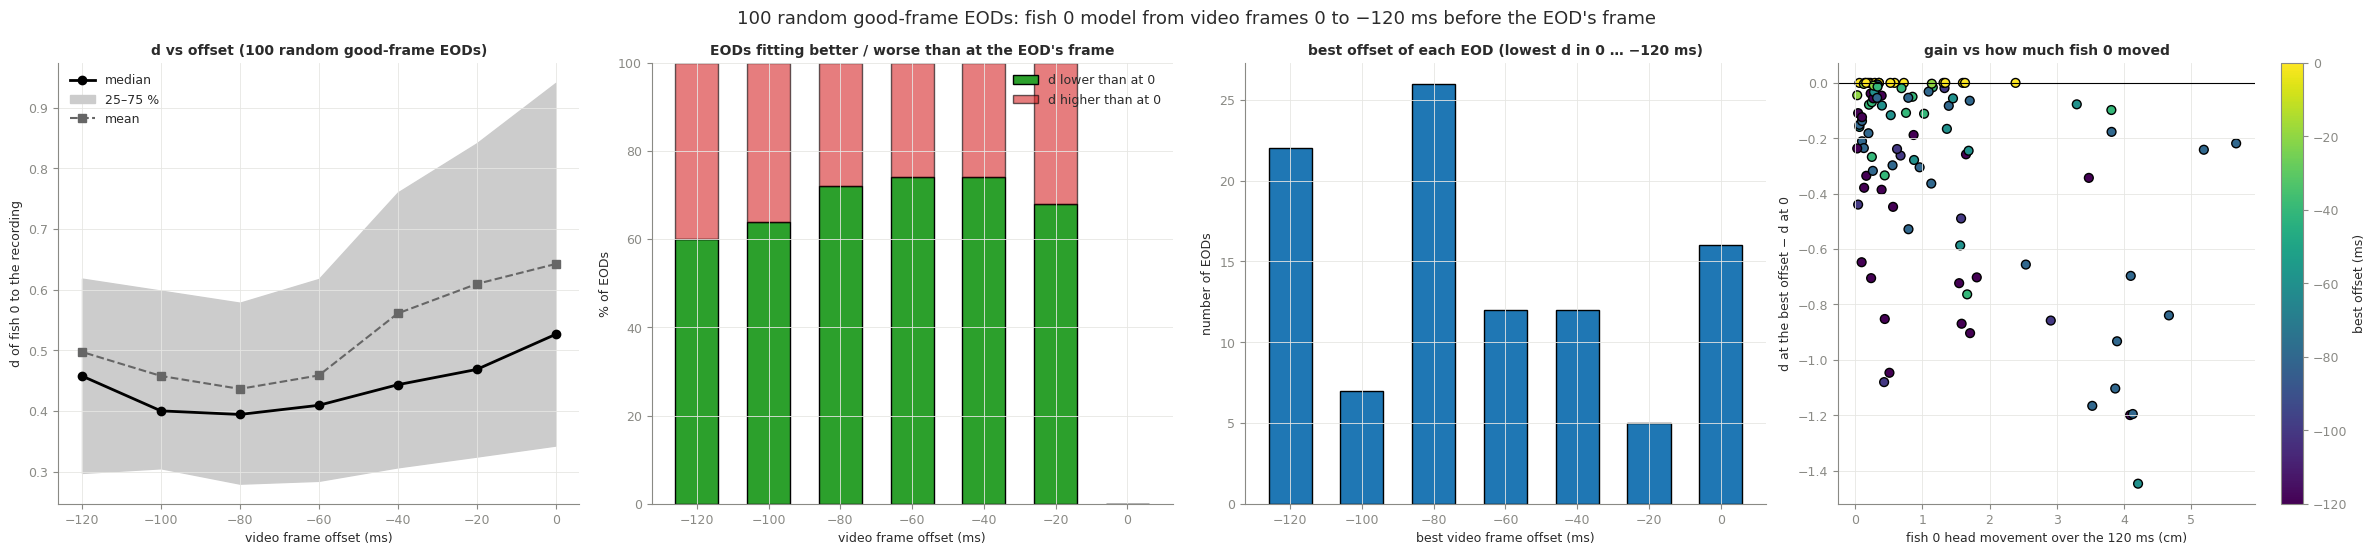

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(24, 5.6))
xs = [1000 * o / c['fps'] for o in OFFSETS]; CH = D - D[:, [0]]
a = axs[0]
a.plot(xs, np.nanmedian(D, axis=0), 'o-', color='k', lw=2, label='median')
a.fill_between(xs, np.nanpercentile(D, 25, axis=0), np.nanpercentile(D, 75, axis=0), color='0.8', label='25–75 %')
a.plot(xs, np.nanmean(D, axis=0), 's--', color='0.4', label='mean')
a.set(xlabel='video frame offset (ms)', ylabel=f'd of fish {em} to the recording', title=f'd vs offset ({len(T)} random good-frame EODs)'); a.legend(fontsize=9)
a = axs[1]
a.bar(xs, [np.nanmean(CH[:, k] < 0) * 100 for k in range(len(OFFSETS))], width=12, color='tab:green', edgecolor='k', label='d lower than at 0')
a.bar(xs, [np.nanmean(CH[:, k] > 0) * 100 for k in range(len(OFFSETS))], width=12, bottom=[np.nanmean(CH[:, k] < 0) * 100 for k in range(len(OFFSETS))],
      color='tab:red', edgecolor='k', alpha=0.6, label='d higher than at 0')
a.set(xlabel='video frame offset (ms)', ylabel='% of EODs', ylim=(0, 100), title='EODs fitting better / worse than at the EOD\'s frame'); a.legend(fontsize=9)
a = axs[2]
a.bar([1000 * o / c['fps'] for o in OFFSETS], [(T.best_off == o).sum() for o in OFFSETS], width=12, color='tab:blue', edgecolor='k')
a.set(xlabel='best video frame offset (ms)', ylabel='number of EODs', title='best offset of each EOD (lowest d in 0 … −120 ms)')
a = axs[3]
sc = a.scatter(T.head_moved_cm, T.gain_best, c=T.best_off * 1000 / c['fps'], cmap='viridis', s=40, edgecolor='k')
plt.colorbar(sc, ax=a, label='best offset (ms)'); a.axhline(0, color='k', lw=0.8)
a.set(xlabel=f'fish {em} head movement over the 120 ms (cm)', ylabel='d at the best offset − d at 0', title='gain vs how much fish 0 moved')
fig.suptitle(f'{len(T)} random good-frame EODs: fish {em} model from video frames 0 to −120 ms before the EOD\'s frame', fontsize=13)
plt.tight_layout(); fig.savefig(f'{OUT}/offset_sweep_random100.png', dpi=100, bbox_inches='tight'); plt.show()